# Ejercicio 10: Aplicación final, reconstruir una imagen desconocida

Se abandona el modelo binario: ahora a_rj es la longitud del tramo del rayo r dentro del píxel j, de modo que b_r es la suma sobre j de a_rj * x_j. Los datos (datos_tomografia_final_128.npz) y la función de carga (cargar_datos_tomografia.py) tienen que estar en la misma carpeta que este notebook.

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110})

## Inciso a) Carga de datos y verificación de dimensiones

In [ ]:
from cargar_datos_tomografia import cargar_datos_tomografia   # funcion provista por la cátedra

datos = cargar_datos_tomografia("datos_tomografia_final_128.npz")

n       = datos["n"]
# A se queda rala todo el tiempo, nunca la paso a densa
A       = datos["A"].tocsr()
b       = np.asarray(datos["b"], dtype=float).ravel()
thetas  = np.asarray(datos["angulos"], dtype=float)
s_pos   = np.asarray(datos["posiciones_detector"], dtype=float)
ruido_norma = datos["norma_ruido_esperada"]      # estimacion de ||eta||

K, q = len(thetas), len(s_pos)
m = K * q
print(f"n = {n},  K = {K} ángulos,  q = {q} posiciones de detector,  m = Kq = {m}")
assert A.shape == (K * q, n ** 2), A.shape
assert b.shape == (K * q,), b.shape
print(f"A: {A.shape}, dispersa, {A.nnz} no nulos ({100*A.nnz/(A.shape[0]*A.shape[1]):.2f} % de ocupación)")
print(f"b: {b.shape}")
print(f"norma esperada del ruido ||eta|| ~ {ruido_norma:.3f}   (||b|| = {np.linalg.norm(b):.3f})")

n = 128,  K = 90 ángulos,  q = 183 posiciones de detector,  m = Kq = 16470
A: (16470, 16384), dispersa, 1876712 no nulos (0.70 % de ocupación)
b: (16470,)
norma esperada del ruido ||eta|| ~ 75.967   (||b|| = 3798.507)


## Inciso b) Sinograma

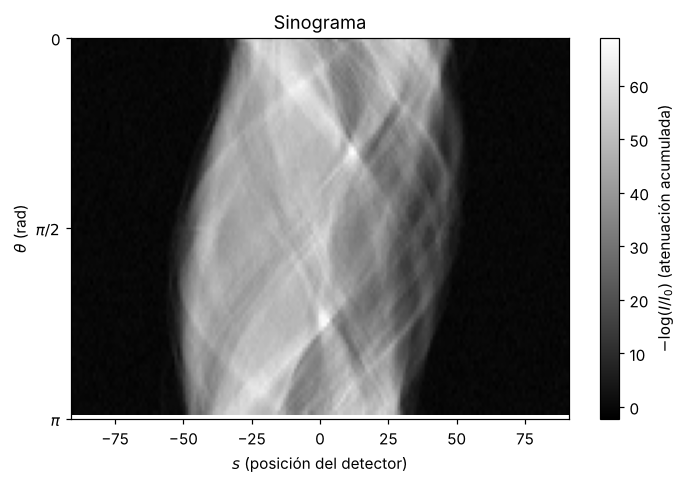

In [3]:
S = b.reshape(K, q)                 # fila k: ángulo theta_k; columna j: posición s_j
assert np.allclose(S[2, 5], b[2 * q + 5])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(S, aspect="auto", cmap="gray",
               extent=[s_pos[0], s_pos[-1], thetas[-1], thetas[0]])   # theta crece hacia abajo (como en la Figura 4)
ax.set_xlabel("$s$ (posición del detector)"); ax.set_ylabel(r"$\theta$ (rad)")
ax.set_yticks([0, np.pi / 2, np.pi]); ax.set_yticklabels(["0", r"$\pi/2$", r"$\pi$"])
ax.set_title("Sinograma"); plt.colorbar(im, label=r"$-\log(I/I_0)$ (atenuación acumulada)")
plt.tight_layout(); plt.savefig("figuras/ejercicio_10_sinograma.png", dpi=150); plt.show()

Las trazas sinusoidales corresponden a las estructuras de la imagen: al variar theta, la posición s en la que cada punto del objeto proyecta describe una sinusoide, y las estructuras más atenuantes producen trazas más intensas. Cada fila del sinograma es un ángulo y cada columna una posición del detector, por eso S[k, j] = b[k*q + j].

## Inciso c) Matriz de diferencias dispersa

In [4]:
def matriz_diferencias(n):
    # D = [Dh; Dv] dispersa en R^{2n(n-1) x n^2}; cada fila tiene un -1 y un +1.
    idx = np.arange(n * n).reshape(n, n)
    # horizontales: X[i, j+1] - X[i, j]
    k_h = idx[:, :-1].ravel()
    # verticales: X[i+1, j] - X[i, j]
    k_v = idx[:-1, :].ravel()
    k0 = np.concatenate([k_h, k_v])
    k1 = np.concatenate([k_h + 1, k_v + n])
    filas = np.arange(len(k0))
    f = np.concatenate([filas, filas]); c = np.concatenate([k0, k1])
    v = np.concatenate([-np.ones(len(k0)), np.ones(len(k0))])
    return sp.csr_matrix((v, (f, c)), shape=(len(k0), n * n))

D = matriz_diferencias(n)
print("D.shape =", D.shape, "| esperado:", (2 * n * (n - 1), n ** 2))

D.shape = (32512, 16384) | esperado: (32512, 16384)


## Inciso d) Gradiente descendiente

Minimizamos J(x) = 1/2 * (||A x - b||^2 + lambda * ||D x||^2), cuyo gradiente es A^T (A x - b) + lambda * D^T D x. Nunca se forma A^T A densa: solo se hacen productos matriz-vector con matrices dispersas. La tasa de aprendizaje es alpha = 1/L, donde L es el mayor autovalor de A^T A + lambda D^T D, calculado con eigsh sobre un operador lineal. Es estable porque L es la constante de Lipschitz del gradiente, y alpha <= 1/L garantiza descenso monótono.

El criterio de parada es que la norma del gradiente sea <= 1e-6 * ||A^T b||, o que la variación relativa del costo sea < 1e-12, o llegar a MAX_ITER iteraciones. Se parte de x0 = 0.

In [5]:
# armo las transpuestas una sola vez, asi no se recalculan en cada iteracion
At = A.T.tocsr()
DtD = (D.T @ D).tocsr()
Atb = At @ b
MAX_ITER, TOL_GRAD, TOL_COSTO = 5000, 1e-6, 1e-12

def grad_J(x, lam):
    return At @ (A @ x - b) + lam * (DtD @ x)

def costo_J(x, lam):
    r = A @ x - b
    return 0.5 * (r @ r + lam * np.sum((D @ x) ** 2))

def constante_L(lam):
    op = spla.LinearOperator((n ** 2, n ** 2), matvec=lambda x: At @ (A @ x) + lam * (DtD @ x), dtype=float)
    return float(spla.eigsh(op, k=1, which="LA", return_eigenvectors=False)[0])

def gd(lam, alpha, max_iter=MAX_ITER):
    x = np.zeros(n ** 2)
    g0 = np.linalg.norm(Atb)
    c_prev = costo_J(x, lam)
    motivo = "max_iter"
    for t in range(1, max_iter + 1):
        g = grad_J(x, lam)
        if np.linalg.norm(g) <= TOL_GRAD * g0:
            motivo = "gradiente"; t -= 1; break
        x = x - alpha * g
        if t % 10 == 0:
            c = costo_J(x, lam)
            if abs(c_prev - c) <= TOL_COSTO * max(1.0, abs(c)):
                motivo = "costo"; break
            c_prev = c
    return x, t, motivo

lambda=0: alpha = 1/L = 8.99e-05, iteraciones = 5000, parada por 'max_iter'
||Ax-b|| = 41.2307,  ||Dx|| = 35.2698,  min = -0.4480, max = 1.3311


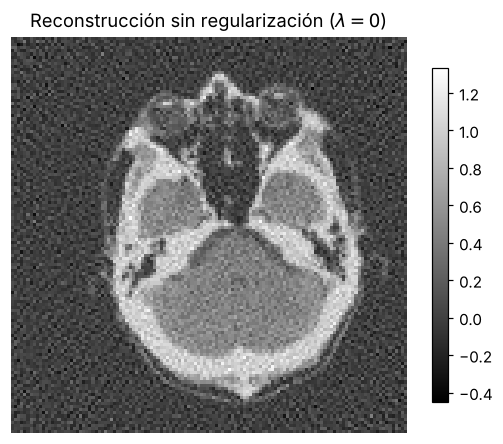

In [6]:
L0 = constante_L(0.0)
x0_rec, it0, mot0 = gd(0.0, 1.0 / L0)
X0 = x0_rec.reshape(n, n)
print(f"lambda=0: alpha = 1/L = {1/L0:.4g}, iteraciones = {it0}, parada por '{mot0}'")
print(f"||Ax-b|| = {np.linalg.norm(A@x0_rec-b):.4f},  ||Dx|| = {np.linalg.norm(D@x0_rec):.4f},  min = {x0_rec.min():.4f}, max = {x0_rec.max():.4f}")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(X0, cmap="gray"); ax.set_title(r"Reconstrucción sin regularización ($\lambda=0$)"); ax.axis("off")
plt.colorbar(im, shrink=0.8); plt.tight_layout(); plt.show()

Primero reconstruimos sin regularización (lambda = 0). En ese caso el problema está mal condicionado: el método tiende a ajustar todas las mediciones, ruido incluido, y la imagen suele resultar granular, con valores negativos y artefactos en forma de rayas a lo largo de las direcciones de los rayos (se ve en la figura). Si el algoritmo termina por max_iter en lugar de por tolerancia, el resultado es una solución parcialmente convergida, lo que actúa como una regularización implícita (parada temprana).

## Inciso e) y f) Reconstrucciones regularizadas y tabla de resultados

In [7]:
lambdas = [0.1, 1, 10, 30, 100]          # la grilla del enunciado, despues agrego intermedios
recs = {0.0: dict(x=x0_rec, alpha=1 / L0, it=it0, motivo=mot0)}

for lam in lambdas:
    a = 1.0 / constante_L(lam)
    x, it, mot = gd(lam, a)
    recs[lam] = dict(x=x, alpha=a, it=it, motivo=mot)
    print(f"lambda = {lam:<6}: alpha = {a:.4g}, it = {it}, parada por '{mot}'")

def tabla(recs):
    filas = []
    for lam in sorted(recs):
        x = recs[lam]["x"]
        filas.append((lam, recs[lam]["alpha"], recs[lam]["it"], recs[lam]["motivo"], np.linalg.norm(A @ x - b),
                      np.linalg.norm(D @ x), x.min(), x.max()))
    return filas

print(f"\n{'lambda':>8}{'alpha':>10}{'iter':>7}{'parada':>11}{'||Ax-b||':>11}{'||Dx||':>10}{'min':>9}{'max':>9}")
for f in tabla(recs):
    print(f"{f[0]:>8g}{f[1]:>10.4g}{f[2]:>7d}{f[3]:>11}{f[4]:>11.4f}{f[5]:>10.4f}{f[6]:>9.4f}{f[7]:>9.4f}")
print(f"\nEstimación de la norma del ruido ||eta|| ~ {ruido_norma:.4f}")

lambda = 0.1   : alpha = 8.99e-05, it = 5000, parada por 'max_iter'


lambda = 1     : alpha = 8.99e-05, it = 5000, parada por 'max_iter'


lambda = 10    : alpha = 8.99e-05, it = 1649, parada por 'gradiente'


lambda = 30    : alpha = 8.989e-05, it = 711, parada por 'gradiente'


lambda = 100   : alpha = 8.989e-05, it = 372, parada por 'gradiente'

  lambda     alpha   iter     parada   ||Ax-b||    ||Dx||      min      max
       0  8.99e-05   5000   max_iter    41.2307   35.2698  -0.4480   1.3311
     0.1  8.99e-05   5000   max_iter    41.6309   33.3783  -0.4185   1.3116
       1  8.99e-05   5000   max_iter    44.5743   25.6031  -0.2809   1.2101
      10  8.99e-05   1649  gradiente    55.3848   18.4989  -0.1502   1.1088
      30 8.989e-05    711  gradiente    71.5334   15.1211  -0.1041   1.0768
     100 8.989e-05    372  gradiente   102.6327   11.4685  -0.0627   1.0506

Estimación de la norma del ruido ||eta|| ~ 75.9669


Comparación con el ruido. Una reconstrucción que ajusta bien los datos debería dejar un residuo de tamaño comparable a la norma del ruido. Un residuo << ||eta|| indica que se está ajustando el ruido (sobreajuste, lambda chico). Un residuo >> ||eta|| indica que se está suavizando de más y perdiendo información real (lambda grande). Esto es el principio de discrepancia de Morozov, que usamos abajo para elegir lambda sin conocer la imagen original.

In [8]:
# Se puede explorar una grilla más fina alrededor de la zona donde ||Ax-b|| cruza la estimación del ruido.
filas = tabla(recs)
res_arr = np.array([f[4] for f in filas]); lam_arr = np.array([f[0] for f in filas])
# me fijo entre que lambdas el residuo cruza la norma del ruido
cruce = np.where((res_arr[:-1] - ruido_norma) * (res_arr[1:] - ruido_norma) < 0)[0]
if len(cruce):
    lo, hi = lam_arr[cruce[0]], lam_arr[cruce[0] + 1]
    print(f"El residuo cruza la estimación del ruido entre lambda = {lo:g} y lambda = {hi:g}; se agregan valores intermedios.")
    extra = [l for l in np.geomspace(max(lo, 1e-3), hi, 5)[1:-1]]
    for lam in extra:
        lam = float(np.round(lam, 3))
        if lam in recs: continue
        a = 1.0 / constante_L(lam); x, it, mot = gd(lam, a)
        recs[lam] = dict(x=x, alpha=a, it=it, motivo=mot)
        print(f"  lambda = {lam:<8}: it = {it}, parada por '{mot}'")
else:
    print("El residuo no cruza la estimación del ruido dentro de la grilla; se mantiene la grilla original.")

print(f"\n{'lambda':>8}{'alpha':>10}{'iter':>7}{'parada':>11}{'||Ax-b||':>11}{'||Dx||':>10}{'min':>9}{'max':>9}")
for f in tabla(recs):
    print(f"{f[0]:>8g}{f[1]:>10.4g}{f[2]:>7d}{f[3]:>11}{f[4]:>11.4f}{f[5]:>10.4f}{f[6]:>9.4f}{f[7]:>9.4f}")

El residuo cruza la estimación del ruido entre lambda = 30 y lambda = 100; se agregan valores intermedios.


  lambda = 40.536  : it = 582, parada por 'gradiente'


  lambda = 54.772  : it = 489, parada por 'gradiente'


  lambda = 74.008  : it = 422, parada por 'gradiente'

  lambda     alpha   iter     parada   ||Ax-b||    ||Dx||      min      max
       0  8.99e-05   5000   max_iter    41.2307   35.2698  -0.4480   1.3311
     0.1  8.99e-05   5000   max_iter    41.6309   33.3783  -0.4185   1.3116
       1  8.99e-05   5000   max_iter    44.5743   25.6031  -0.2809   1.2101
      10  8.99e-05   1649  gradiente    55.3848   18.4989  -0.1502   1.1088
      30 8.989e-05    711  gradiente    71.5334   15.1211  -0.1041   1.0768
  40.536 8.989e-05    582  gradiente    78.0696   14.1657  -0.0939   1.0641
  54.772 8.989e-05    489  gradiente    85.4736   13.2290  -0.0834   1.0589
  74.008 8.989e-05    422  gradiente    93.6807   12.3264  -0.0729   1.0547
     100 8.989e-05    372  gradiente   102.6327   11.4685  -0.0627   1.0506


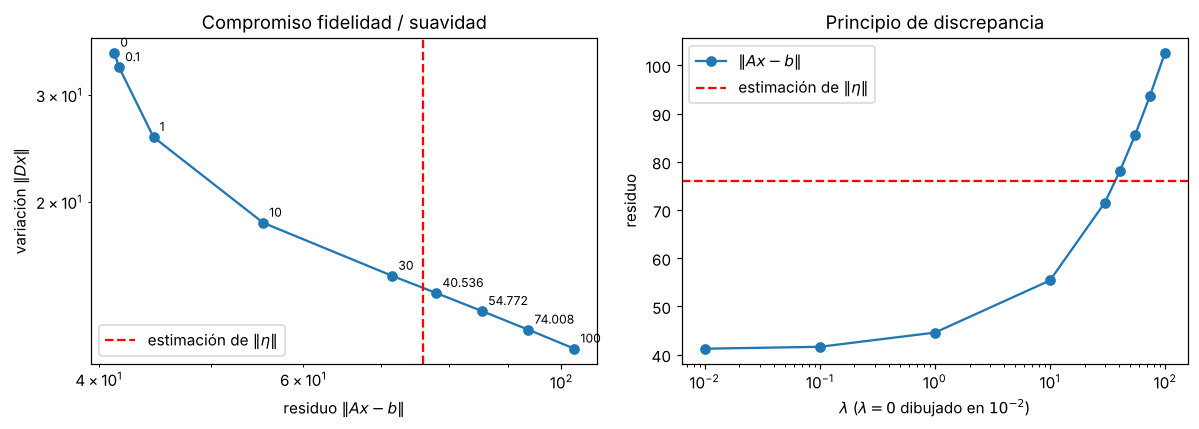

In [9]:
# Curva de compromiso (L-curve): variación ||Dx|| vs. residuo ||Ax-b||
filas = tabla(recs)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog([f[4] for f in filas], [f[5] for f in filas], "o-")
for f in filas: ax[0].annotate(f"{f[0]:g}", (f[4], f[5]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax[0].axvline(ruido_norma, color="r", ls="--", label=r"estimación de $\|\eta\|$")
ax[0].set_xlabel(r"residuo $\|Ax-b\|$"); ax[0].set_ylabel(r"variación $\|Dx\|$"); ax[0].legend(); ax[0].set_title("Compromiso fidelidad / suavidad")
ax[1].semilogx([max(f[0], 1e-2) for f in filas], [f[4] for f in filas], "o-", label=r"$\|Ax-b\|$")
ax[1].axhline(ruido_norma, color="r", ls="--", label=r"estimación de $\|\eta\|$")
ax[1].set_xlabel(r"$\lambda$ ($\lambda=0$ dibujado en $10^{-2}$)"); ax[1].set_ylabel("residuo"); ax[1].legend(); ax[1].set_title("Principio de discrepancia")
plt.tight_layout(); plt.savefig("figuras/ejercicio_10_compromiso.png", dpi=150); plt.show()

## Inciso g) Elección de la reconstrucción y figura final

El criterio no usa la imagen original: se toma el lambda > 0 cuyo residuo es más cercano a la estimación de la norma del ruido (principio de discrepancia), y después se verifica visualmente que no se pierdan estructuras ni quede ruido granular. La figura muestra el sinograma, la reconstrucción sin regularizar, el lambda elegido y sus vecinos en la grilla.

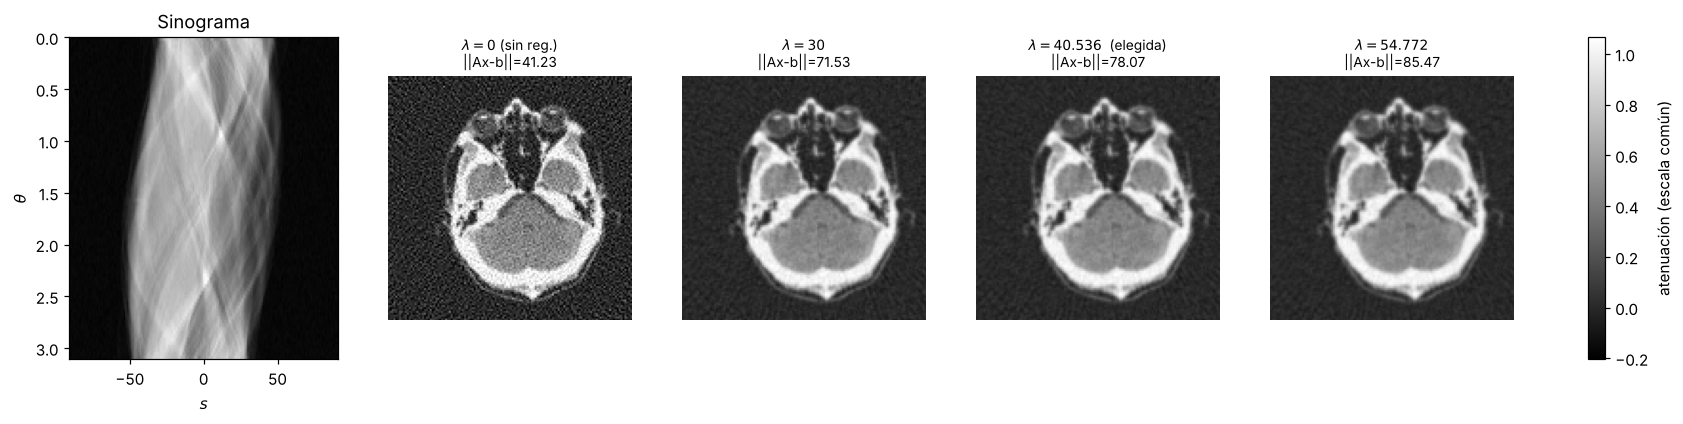

In [10]:
cand = sorted(l for l in recs if l > 0)
disc = {l: abs(np.log(np.linalg.norm(A @ recs[l]["x"] - b) / ruido_norma)) for l in cand}
lam_elegido = min(disc, key=disc.get)
i = cand.index(lam_elegido)
vecinos = cand[max(0, min(i - 1, len(cand) - 3)): max(0, min(i - 1, len(cand) - 3)) + 3] if len(cand) >= 3 else cand
mostrar = [0.0] + vecinos

# Escala de color común (percentiles del conjunto de imágenes mostradas, para que un par de píxeles extremos no domine)
pool = np.concatenate([recs[l]["x"] for l in mostrar])
VMIN, VMAX = np.percentile(pool, 0.5), np.percentile(pool, 99.5)

fig, axes = plt.subplots(1, 2 + len(mostrar), figsize=(3.4 * (2 + len(mostrar)), 3.8),
                         gridspec_kw={"width_ratios": [1.1] + [1] * (1 + len(mostrar))})
axes[0].imshow(S, aspect="auto", cmap="gray", extent=[s_pos[0], s_pos[-1], thetas[-1], thetas[0]])
axes[0].set_title("Sinograma"); axes[0].set_xlabel("$s$"); axes[0].set_ylabel(r"$\theta$")
for ax, lam in zip(axes[1:], mostrar):
    x = recs[lam]["x"]
    h = ax.imshow(x.reshape(n, n), cmap="gray", vmin=VMIN, vmax=VMAX); ax.axis("off")
    etiqueta = r"$\lambda=0$ (sin reg.)" if lam == 0 else rf"$\lambda={lam:g}$" + ("  (elegida)" if lam == lam_elegido else "")
    ax.set_title(etiqueta + f"\n||Ax-b||={np.linalg.norm(A@x-b):.2f}", fontsize=9)
axes[-1].axis("off")
fig.colorbar(h, ax=axes[-1], fraction=0.9, label="atenuación (escala común)")
plt.savefig("figuras/ejercicio_10_final.png", dpi=150, bbox_inches="tight"); plt.show()

In [11]:
r_e = np.linalg.norm(A @ recs[lam_elegido]["x"] - b); v_e = np.linalg.norm(D @ recs[lam_elegido]["x"])
r_0 = np.linalg.norm(A @ recs[0.0]["x"] - b);          v_0 = np.linalg.norm(D @ recs[0.0]["x"])
print(f"lambda elegido = {lam_elegido:g}")
print(f"norma del ruido estimada = {ruido_norma:.3f}")
print(f"residuo con lambda elegido = {r_e:.3f}  (cociente {r_e/ruido_norma:.2f})")
print(f"residuo sin regularizar    = {r_0:.3f}  (cociente {r_0/ruido_norma:.2f})")
print(f"variacion ||Dx||: {v_0:.2f} sin regularizar -> {v_e:.2f} con lambda elegido")
print(f"minimo de la imagen: {recs[0.0]['x'].min():.3f} sin regularizar -> {recs[lam_elegido]['x'].min():.3f} con lambda elegido")

lambda elegido = 40.536
norma del ruido estimada = 75.967
residuo con lambda elegido = 78.070  (cociente 1.03)
residuo sin regularizar    = 41.231  (cociente 0.54)
variacion ||Dx||: 35.27 sin regularizar -> 14.17 con lambda elegido
minimo de la imagen: -0.448 sin regularizar -> -0.094 con lambda elegido


Este criterio es una heurística: el principio de discrepancia depende de que la estimación del ruido sea buena, y el lambda óptimo en error real puede ser algo distinto. Por eso se contrasta con la inspección visual y con la curva de compromiso: el lambda elegido debería estar cerca del codo de la curva de variación de la imagen contra residuo. Con lambdas más chicos queda ruido granular visible (residuo por debajo de la norma del ruido) y con los más grandes la imagen se vuelve borrosa y se achatan los máximos (residuo por encima); el elegido es el punto de equilibrio donde se conservan los bordes y las regiones principales con poco ruido.